# Описание

Необходимо разработать функцию вознаграждения и обучить интеллектуального агента, управляющего роботом-пылесосом, для выполнения задачи уборки помещения.

В помещении расположены три скопления мусора и ковёр, на котором находится спящий кот. Заезд робота на ковёр считается нарушением ограничения и приводит к неуспешному завершению эпизода.

Функция вознаграждения должна стимулировать сбор мусора и завершение уборки, а также препятствовать бесцельному перемещению и заезду в запрещённую зону.

Критерием успешного выполнения задачи является сбор всех трёх скоплений мусора без заезда на ковёр. Эффективность обученного агента необходимо подтвердить результатами тестирования.

# Постановка задачи

Среда, с которой мы будем работать, будет представлять комнату в виде сетки размера 8x8. Синим кружочком мы будем обозначать положение робота-пылесоса, красными квадратами — мусор, который надо собрать, а жёлтым квадратом — кота на которого нельзя наступать

### Описание среды

In [ ]:
# Ячейка 1: Установка и импорты
!pip install gymnasium numpy matplotlib -q

import gymnasium as gym
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from enum import IntEnum
from IPython.display import HTML, clear_output
import matplotlib.animation as animation
from IPython.display import HTML, display, clear_output

In [ ]:
class LazyRobotEnv(gym.Env):
    """
    Комната 8x8 с 4 кучками мусора и котом.
    Если робот заезжает на клетку с котом – эпизод досрочно завершается (truncated).
    Награда по умолчанию +1000 за любое действие.
    """
    metadata = {"render_modes": ["rgb_array"], "render_fps": 4}

    def __init__(self, render_mode=None):
        super().__init__()
        self.size = 8
        self.dirt_positions = [(1, 1), (3, 2), (7, 3), (5, 6)]
        self.cat_pos = (4, 4)                # кот статичен
        self.max_steps = 100

        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.MultiDiscrete([8, 8,2, 2, 2, 2])
        self.render_mode = render_mode
        self._current_frame = None

    def get_obs(self):
        """Текущее наблюдение (используется враппером награды)."""
        return self._get_obs()

    def _get_obs(self):
        return np.array([
            self.agent_pos[0], self.agent_pos[1],
            self.dirt_status[0], self.dirt_status[1], self.dirt_status[2],self.dirt_status[3]
        ], dtype=np.int32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.agent_pos = [0, 0]
        self.dirt_status = [1, 1, 1, 1]
        self.steps = 0
        obs = self._get_obs()
        if self.render_mode == "rgb_array":
            self._current_frame = self._render_frame()
        return obs, {}

    def step(self, action):
        x, y = self.agent_pos
        if action == Action.UP:
            y = max(0, y - 1)
        elif action == Action.RIGHT:
            x = min(self.size - 1, x + 1)
        elif action == Action.DOWN:
            y = min(self.size - 1, y + 1)
        elif action == Action.LEFT:
            x = max(0, x - 1)
        self.agent_pos = [x, y]

        # Проверка столкновения с котом
        cat_hit = (self.agent_pos[0] == self.cat_pos[0] and
                   self.agent_pos[1] == self.cat_pos[1])

        # Уборка мусора
        for i, pos in enumerate(self.dirt_positions):
            if self.agent_pos == list(pos) and self.dirt_status[i] == 1:
                self.dirt_status[i] = 0

        # Глупая награда (будет переопределена враппером)
        reward = 1000.0
        done = all(s == 0 for s in self.dirt_status)
        self.steps += 1
        truncated = self.steps >= self.max_steps or cat_hit

        info = {
            "dirt_status": self.dirt_status.copy(),
            "cat_hit": cat_hit
        }

        obs = self._get_obs()
        if self.render_mode == "rgb_array":
            self._current_frame = self._render_frame()

        return obs, reward, done, truncated, info

    def render(self):
        if self.render_mode == "rgb_array":
            return self._current_frame
        raise NotImplementedError("Поддерживается только rgb_array")

    def _render_frame(self):
        """Отрисовка комнаты с мусором, роботом и котом."""
        fig, ax = plt.subplots(figsize=(3, 3))
        ax.set_xlim(0, self.size)
        ax.set_ylim(0, self.size)
        ax.set_xticks(np.arange(self.size))
        ax.set_yticks(np.arange(self.size))
        ax.grid(True)

        # Мусор
        for i, (dx, dy) in enumerate(self.dirt_positions):
            if self.dirt_status[i]:
                rect = Rectangle((dx, self.size - 1 - dy), 1, 1,
                                 facecolor='brown', alpha=0.7)
                ax.add_patch(rect)

        # Кот
        cat_x, cat_y = self.cat_pos
        ax.add_patch(Rectangle((cat_x, self.size - 1 - cat_y), 1, 1,
                               facecolor='orange', alpha=0.9, edgecolor='black'))
        ax.text(cat_x + 0.5, self.size - 1 - cat_y + 0.5, '😾',
                ha='center', va='center', fontsize=20)

        # Робот
        ax.add_patch(Circle(
            (self.agent_pos[0] + 0.5, self.size - 1 - self.agent_pos[1] + 0.5),
            0.4, color='blue'
        ))

        ax.set_aspect('equal')
        fig.canvas.draw()
        buf = np.frombuffer(fig.canvas.buffer_rgba(), dtype=np.uint8)
        img = buf.reshape(*fig.canvas.get_width_height()[::-1], 4)[..., :3]
        plt.close(fig)
        return img

### Описание действий

In [ ]:
class Action(IntEnum):
    """Возможные действия робота."""
    UP = 0      # шаг вверх
    RIGHT = 1   # шаг вправо
    DOWN = 2    # шаг вниз
    LEFT = 3    # шаг влево

### Запуск среды

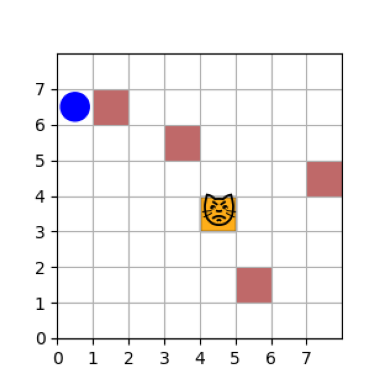

In [ ]:
# Создаём среду и включаем режим отрисовки
env = LazyRobotEnv(render_mode="rgb_array")

# Сбрасываем её (стартовая позиция)
obs, _ = env.reset()
obs, reward, done, truncated, info = env.step(Action.DOWN)

# Получаем кадр текущего состояния
frame = env.render()

# Выводим
import matplotlib.pyplot as plt
plt.imshow(frame)
plt.axis('off')
plt.show()

### Награда

In [ ]:
class CustomRewardWrapper(gym.Wrapper):
    """
    Позволяет переопределить награду.
    reward_fn(old_obs, action, new_obs, info) -> float
    """
    def __init__(self, env, reward_fn):
        super().__init__(env)
        self.reward_fn = reward_fn

    def step(self, action):
        old_obs = self.env.get_obs()
        obs, _, done, truncated, info = self.env.step(action)
        reward = self.reward_fn(old_obs, action, obs, info)
        return obs, reward, done, truncated, info

In [ ]:
def dummy_reward(old_obs, action, new_obs, info):
    return 1000

### Агент

In [ ]:
class DownAgent:
    """Агент, выбирающий действие случайно."""
    def get_action(self, state, training=True):
        # Пока что state игнорируется, работаем только с действиями: UP, RIGHT, DOWN, LEFT
        return Action.DOWN

### Отрисовка результата

In [ ]:
def evaluate(agent, num_episodes=100):
    """
    Метрика: доля успешных уборок до истечения 100 шагов и среднее число шагов.
    Использует базовую среду (без враппера награды).
    """
    env = LazyRobotEnv()
    successes = 0
    steps_list = []
    for _ in range(num_episodes):
        obs, _ = env.reset()
        done, truncated = False, False
        steps = 0
        while not (done or truncated):
            action = agent.get_action(obs, training=False)
            obs, _, done, truncated, _ = env.step(action)
            steps += 1
        if done:   # всё чисто
            successes += 1
            steps_list.append(steps)
    success_rate = successes / num_episodes
    avg_steps = np.mean(steps_list) if steps_list else float('inf')
    return success_rate, avg_steps


def run_episode_for_animation(agent):
    """Прогоняет эпизод и собирает кадры."""
    env = LazyRobotEnv(render_mode="rgb_array")
    obs, _ = env.reset()
    frames = [env.render()]
    done, truncated = False, False
    while not (done or truncated):
        action = agent.get_action(obs, training=False)
        obs, _, done, truncated, _ = env.step(action)
        frames.append(env.render())
    return frames


def show_animation(frames, fps=4):
    fig, ax = plt.subplots()
    plt.axis('off')
    im = ax.imshow(frames[0])
    def animate(i):
        im.set_data(frames[i])
        return [im]
    anim = animation.FuncAnimation(fig, animate, frames=len(frames),
                                   interval=1000/fps, blit=True)
    plt.close(fig)
    return HTML(anim.to_html5_video())

### Обучение

In [ ]:
env = LazyRobotEnv()
wrapped_env = CustomRewardWrapper(env, dummy_reward)
agent = DownAgent()

In [ ]:
# Оценка бейзлайна
sr, avg = evaluate(agent)
print(f"Бейзлайн: успешных уборок {sr*100:.1f}%, среднее шагов {avg:.1f}")

# Анимация одного примера
frames = run_episode_for_animation(agent)
show_animation(frames)

Бейзлайн: успешных уборок 0.0%, среднее шагов inf


# 3. Решение

Сначала изменим награду. Наша задача за минимальное количество шаго(значит будем наказывать за каждый шаг) Убрать все кучи(будем награждаться за их уборку), при этом нельзя сталкиваться с котом(возьмем огромный штраф что бы ни в коем разе не наступить на кота)

In [ ]:
def custom_reward(old_obs, action, new_obs, info):
    #1 штраф за каждый шаг (что бы действовать быстрее)
    reward = -1.0
    #2 огромный штраф за столкновение с котом
    if info.get("cat_hit", False):
        reward -= 150.0
        return reward # завершаем если врезались

    #3 награда за уборку мусора
    #сравниваем количество мусора до и после
    old_dirt_count = np.sum(old_obs[2:])
    new_dirt_count = np.sum(new_obs[2:])

    if new_dirt_count < old_dirt_count:
        reward += 50.0 #награда за каждую убранную кучку

    if new_dirt_count == 0:
        reward += 100.0 #доп бонус если все кучи собраны
    return reward

In [ ]:
import random

class QLearningAgent:
    def __init__(self, n_actions=4, epsilon_decay = 0.995,lr=0.1, gamma=0.99, epsilon=1.0, min_epsilon=0.01):
        self.q_table = {}  #словарь для Q-таблицы
        self.lr = lr
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.min_epsilon = min_epsilon
        self.n_actions = n_actions

    def get_q_values(self, state):
        #превращаем массив состояний в кортеж для использования как ключ
        state_key = tuple(state.tolist())
        if state_key not in self.q_table:
            self.q_table[state_key] = np.zeros(self.n_actions)
        return self.q_table[state_key]

    def get_action(self, state, training=True):
        q_values = self.get_q_values(state)
        #епсилон жадная стратегия
        if training and random.random() < self.epsilon:
            return random.randint(0, self.n_actions - 1)
        return int(np.argmax(q_values))

    def update(self, state, action, reward, next_state):
        state_key = tuple(state.tolist())
        next_q_values = self.get_q_values(next_state)

        #текущее значение Q
        current_q = self.get_q_values(state)[action]
        #максимальное ожидаемое значение Q для следующего состояния
        max_next_q = np.max(next_q_values)

        #обновление по формуле с лекции
        self.q_table[state_key][action] = current_q + self.lr * (reward + self.gamma * max_next_q - current_q)

    def decay_epsilon(self):
        #уменьшаем епсилон что бы наш агент только вначале изучал среду, а потом просто ее проходил
        self.epsilon = max(self.min_epsilon, self.epsilon * self.epsilon_decay)

In [ ]:
#инициализация
env = LazyRobotEnv()
wrapped_env = CustomRewardWrapper(env, custom_reward)
agent = QLearningAgent(n_actions=4,epsilon_decay = 0.995)

#на всякий случай
num_episodes = 10000

for episode in range(num_episodes):
    obs, _ = wrapped_env.reset()
    done = False
    truncated = False

    while not (done or truncated):
        action = agent.get_action(obs, training=True)
        new_obs, reward, done, truncated, info = wrapped_env.step(action)
        agent.update(obs, action, reward, new_obs)
        obs = new_obs

    agent.decay_epsilon()

# 4. Проверка работы

In [ ]:
num_test_episodes=200

# Проверка наличия интерфейса
assert hasattr(agent, 'get_action'), "Агент должен иметь метод get_action(state, training)"

# Метрика
success_rate, avg_steps = evaluate(agent, num_test_episodes)
print(f"Результат: уборок завершено {success_rate*100:.1f}%")
if success_rate > 0:
    print(f"Среднее число шагов (успешные): {avg_steps:.1f}")
else:
    print("Агент ни разу не убрал всю комнату 😢")

# Анимация
frames = run_episode_for_animation(agent)
display(show_animation(frames))


Результат: уборок завершено 100.0%
Среднее число шагов (успешные): 15.0
